# Counterfactual Sampling on dSprites: Continuous Actions, Cross-Fitted DR-CPME Target, Riesz MMD Flow (AdamW)

Counterfactual image sampling with a **continuous 2D action**, on the dSprites design of
Zenati et al. (2025, arXiv:2506.02793, Sec. 14.1.5). The continuous action is the native
case for kernel counterfactual policy mean embeddings: the action enters the estimator only
through Gram matrices, so nothing in the DR construction changes relative to the binary
designs. The pipeline:

1. **Data** — logged bandit data $(x_i, a_i, y_i)$ with a Gaussian logging policy; the
   outcome is a rendered sprite image whose position is set by the action.
2. **Autoencoder** — a denoising convolutional autoencoder supplies the feature map: the
   flow runs in its latent space and decodes back to images (pixel-space flow fails on the
   thin sprite manifold in $\mathbb{R}^{4096}$).
3. **Estimation** — the cross-fitted doubly robust embedding
   $\hat\chi_{\mathrm{DR}}(\pi) = \sum_i v_i\,\varphi(z_i)$ over encoded outcomes, with the
   logging density (hence the ratio $\pi/\hat\pi_0$) estimated by cross-fitting.
4. **Sampling** — Riesz-kernel MMD flow over particles, minimised with AdamW + warm-up
   (Hertrich et al., 2024), against the fixed estimated embedding.

## 1. Data

Latent context $x \sim \mathrm{U}([0,1]^2)$. A 2D continuous action is drawn from a
Gaussian policy whose mean depends on $x$ (the confounding channel):

$$\pi_0: a \mid x \sim \mathcal{N}\!\big((x - \tfrac12) - \delta,\ \sigma^2 I_2\big),
\qquad
\pi: a \mid x \sim \mathcal{N}\!\big((x - \tfrac12) + \delta,\ \sigma^2 I_2\big),$$

with $\delta = 0.2$, $\sigma = 0.5$. The action places a heart sprite at position
$(\mathrm{pos}_X, \mathrm{pos}_Y) = \mathrm{round}\big(31\,\mathrm{sigmoid}(3a)\big)$, and
the outcome is the rendered $64 \times 64$ image at that position plus
$\mathcal{N}(0, 0.05^2)$ pixel noise, flattened to $\mathbb{R}^{4096}$. The two policies
place sprites in different regions, so the interventional image law $\nu(\pi)$ differs
visibly from the logged one.

The oracle density ratio $w_i = \pi(a_i \mid x_i)/\pi_0(a_i \mid x_i)$ is analytic and is
kept **for diagnostics only** — estimation below uses an estimated logging density. Two
scope remarks: the context affects the outcome only through the action (no direct
$x \to y$ edge is needed by the estimator), and the target policy must be stochastic — a
deterministic intervention $\mathrm{do}(a^*)$ has no density and degenerates the ratio.

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch

sys.path.append("../../src")
from causality_utils import (cpme_dr_weights_crossfit, make_crossfit_fold_ids,
                             select_regularization)
from data_utils import load_dsprite_bank, sample_cpme_dsprite_data
from dens_ratio_utils import (crossfit_logging_policy_log_prob,
                              importance_weight_diagnostics,
                              importance_weights_from_logging_log_prob)
from autoencoder_utils import (encode_in_batches, nearest_bank_position,
                               position_probe, snap_to_bank, train_dsprite_ae)
from kernel_utils import RBF, RieszKernel
from mmd_flow_utils import adamw_riesz_flow, mmd_gradient_flow, squared_mmd
from metric_utils import sliced_wasserstein

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(0)
np.random.seed(0)
print("device:", device)

device: cuda


n = 1000   oracle weights: mean 0.981   ESS 287   max 23.4


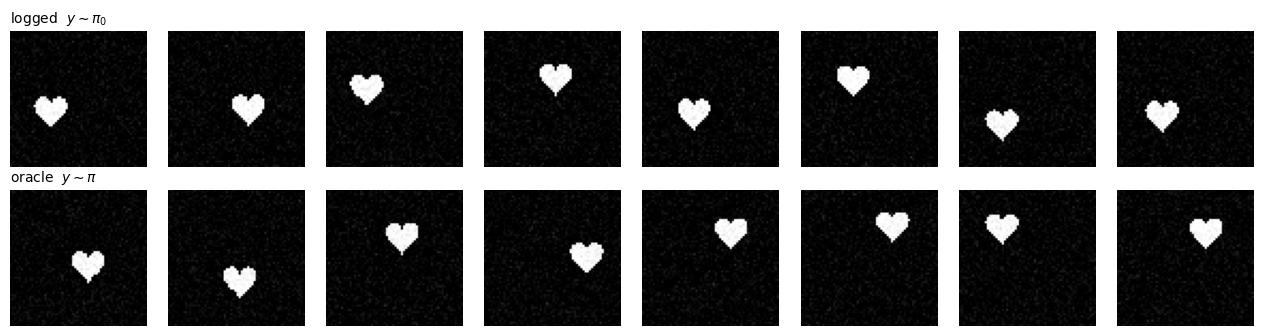

In [2]:
N_OBS = 1000
DSPRITE_NPZ = "../../data/dsprites/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz"
BANK_CACHE = os.path.join(os.path.dirname(DSPRITE_NPZ), "heart_sprite_bank_32x32.npy")

sprite_bank = load_dsprite_bank(DSPRITE_NPZ, cache_path=BANK_CACHE)   # (32, 32, 64, 64)
data = sample_cpme_dsprite_data(sprite_bank, n_samples=N_OBS, sigma_policy=0.5,
                                policy_shift=0.2, pos_gain=3.0, pixel_noise=0.05, seed=1)

oracle_diag = importance_weight_diagnostics(data["importance_weights"].numpy())
print(f"n = {N_OBS}   oracle weights: mean {oracle_diag['mean']:.3f}   "
      f"ESS {oracle_diag['ess']:.0f}   max {oracle_diag['max']:.1f}")

n_show = 8
fig, axes = plt.subplots(2, n_show, figsize=(1.6 * n_show, 3.4))
for j in range(n_show):
    axes[0, j].imshow(data["Y_logged"][j].reshape(64, 64), cmap="gray", vmin=0, vmax=1)
    axes[1, j].imshow(data["Y_target"][j].reshape(64, 64), cmap="gray", vmin=0, vmax=1)
for ax in axes.ravel():
    ax.axis("off")
axes[0, 0].set_title(r"logged  $y \sim \pi_0$", loc="left", fontsize=10)
axes[1, 0].set_title(r"oracle  $y \sim \pi$", loc="left", fontsize=10)
plt.tight_layout()
plt.show()

## 2. Denoising Autoencoder

A symmetric convolutional autoencoder (four stride-2 convolutions to a linear bottleneck
$z \in \mathbb{R}^{32}$, mirrored decoder with a final sigmoid) trained with a
**denoising** objective: reconstruct the clean sprite from a copy corrupted with the same
$0.05$-std pixel noise the DGP adds, so the encoder absorbs the observation noise and the
decoder always renders clean sprites.

Two design decisions. First, the autoencoder is trained on the **full 1024-position sprite
bank**, not the logged sample: it is sampler machinery, not part of the statistical
estimator (the analogue of a pretrained VAE), and the decoder must be able to render
positions that are rare under $\pi_0$ but common under $\pi$. Second, the latent is 32-d
although the sprite manifold is 2-d: reconstruction is perfect from width 8 already, but
the *linear* organisation of the latent — measured by a held-out linear probe
$z \to (\mathrm{pos}_X, \mathrm{pos}_Y)$ — keeps improving with width, and the linear
probe is what predicts feature quality for the kernel.

parameters: 987,873   final training mse 0.00005


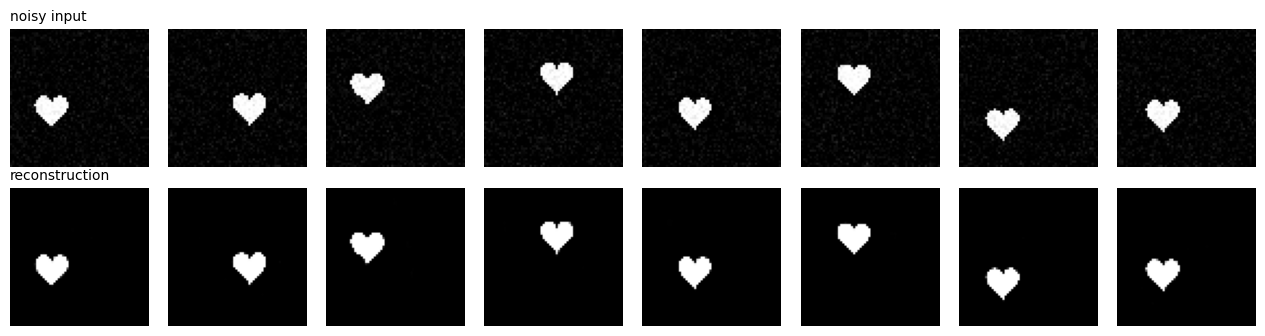

In [3]:
bank_t = torch.as_tensor(sprite_bank, dtype=torch.float32).reshape(1024, 1, 64, 64)
ae, history = train_dsprite_ae(bank_t, latent_dim=32, noise_std=0.05,
                               n_iterations=4000, device=device, verbose=False)
print(f"parameters: {sum(p.numel() for p in ae.parameters()):,}   "
      f"final training mse {history[-1][1]:.5f}")

Y_logged_img = data["Y_logged"].float().reshape(-1, 1, 64, 64).to(device)
Y_target_img = data["Y_target"].float().reshape(-1, 1, 64, 64).to(device)
with torch.no_grad():
    recon_logged = ae(Y_logged_img[:n_show]).cpu()
fig, axes = plt.subplots(2, n_show, figsize=(1.6 * n_show, 3.4))
for j in range(n_show):
    axes[0, j].imshow(Y_logged_img[j, 0].cpu(), cmap="gray", vmin=0, vmax=1)
    axes[1, j].imshow(recon_logged[j, 0], cmap="gray", vmin=0, vmax=1)
for ax in axes.ravel():
    ax.axis("off")
axes[0, 0].set_title("noisy input", loc="left", fontsize=10)
axes[1, 0].set_title("reconstruction", loc="left", fontsize=10)
plt.tight_layout()
plt.show()

In [4]:
bank_flat = bank_t.reshape(1024, -1).to(device)
bank_positions = torch.stack(torch.meshgrid(torch.arange(32), torch.arange(32),
                                            indexing="ij"), dim=-1).reshape(1024, 2)

for name, imgs, pos_true in (("logged", Y_logged_img, data["pos_logged"]),
                             ("target", Y_target_img, data["pos_target"])):
    with torch.no_grad():
        recon = torch.cat([ae(imgs[i:i + 256]) for i in range(0, len(imgs), 256)])
    denoise_mse = float(((recon.reshape(len(imgs), -1)
                          - bank_flat[pos_true[:, 0].long() * 32
                                      + pos_true[:, 1].long()]) ** 2).mean())
    snapped = nearest_bank_position(recon.reshape(len(imgs), -1), bank_flat).cpu()
    exact = float((snapped == pos_true.long()).all(dim=1).float().mean())
    print(f"{name:6s}  denoise mse {denoise_mse:.5f} (input noise mse 0.00250)   "
          f"exact position match {exact:.3f}")

Z_bank = encode_in_batches(ae.encode,
                           (bank_t + 0.05 * torch.randn_like(bank_t)).to(device))
probe = position_probe(Z_bank, bank_positions)
print(f"linear probe R^2: posX {probe['posX_r2']:.3f}   posY {probe['posY_r2']:.3f}")

logged  denoise mse 0.00006 (input noise mse 0.00250)   exact position match 1.000
target  denoise mse 0.00007 (input noise mse 0.00250)   exact position match 1.000


linear probe R^2: posX 0.975   posY 0.921


## 3. Cross-Fitted Doubly Robust Weights

All nuisances share one $K = 5$ fold assignment. With $z_i$ the encoded logged outcome and
$\varphi$ the (implicit) outcome feature map:

- **Density ratio.** The logging policy is estimated per fold as a linear-Gaussian
  conditional density $\hat\pi_0^{(-k)}(a \mid x)$ fit on the other folds; the weight
  $\hat w_i = \pi(A_i \mid X_i) / \hat\pi_0^{(-k_i)}(A_i \mid X_i)$ keeps the **known**
  target policy exact in the numerator. Raw ratios — no normalisation or clipping.
- **Conditional mean embedding.** Per fold, a kernel ridge regression on
  $K = K_X \circ K_A$ restricted to the training block, with the ridge $\lambda_k$
  selected on that block. The target-policy embedding $\hat\mu_\pi^{(-k)}(x_i)$ uses a
  Monte Carlo kernel mean over $\tilde a \sim \pi(\cdot \mid x_i)$ draws — an operation on
  the known policy, independent of any oracle sample.
- **One-step correction.** The pseudo-outcome
  $\hat\Gamma_i = \hat\mu_\pi^{(-k_i)}(X_i)
  + \hat w_i\big(\varphi(z_i) - \hat\mu^{(-k_i)}(X_i, A_i)\big)$ averages to
  $\hat\chi_{\mathrm{DR}}(\pi) = \frac1n \sum_i \hat\Gamma_i = \sum_i v_i\,\varphi(z_i)$ —
  still a single weight vector over the encoded outcomes, which is all the sampler sees
  (`cpme_dr_weights_crossfit`).

The kernel lengthscales and the autoencoder are fit once on all data (not cross-fitted);
only the ratio and the conditional mean embedding are. Because the sprite position enters
no coefficient of the estimator, the reweighted position $\sum_i v_i\,\mathrm{pos}_i$ is a
legitimate check against the interventional position mean.

In [5]:
N_FOLDS = 5
fold_ids = make_crossfit_fold_ids(N_OBS, n_folds=N_FOLDS, seed=0)

X_np = data["X"].numpy()
A_np = data["A_logged"].numpy()
log_pi0_hat = crossfit_logging_policy_log_prob(X_np, A_np, fold_ids=fold_ids)
w_hat = importance_weights_from_logging_log_prob(data["target_policy"], X_np, A_np,
                                                 log_pi0_hat)
diag = importance_weight_diagnostics(w_hat, data["importance_weights"].numpy())
print(f"estimated weights: mean {diag['mean']:.3f}   ESS {diag['ess']:.0f}   "
      f"max {diag['max']:.1f}   log-RMSE vs oracle {diag['log_rmse']:.3f}")

Z_log = encode_in_batches(ae.encode, Y_logged_img).cpu()

kernel_x = RBF(use_length_scale_heuristic=True)
kernel_a = RBF(use_length_scale_heuristic=True)
X_t = data["X"].double()
A_t = data["A_logged"].double()
K_x = kernel_x(X_t)
K_a = kernel_a(A_t)
print(f"lengthscales: l_X {float(kernel_x.length_scale):.3f}   "
      f"l_A {float(kernel_a.length_scale):.3f}")

N_RESAMPLE = 8
resample_rng = np.random.default_rng(0)
K_a_target = torch.zeros(N_OBS, N_OBS, dtype=torch.float64)
for _ in range(N_RESAMPLE):
    A_resample = data["target_policy"].sample(X_np, resample_rng)
    K_a_target += kernel_a(A_t, torch.as_tensor(A_resample, dtype=torch.float64))
K_a_target /= N_RESAMPLE

K_pair = K_x * K_a
fold_lambdas = {}
for fold in np.unique(fold_ids):
    train = np.where(fold_ids != fold)[0]
    fold_lambdas[int(fold)], _ = select_regularization(K_pair[train][:, train],
                                                       Z_log[train, 0].double(), seed=0)
print("per-fold lambdas:", fold_lambdas)

w_t = torch.as_tensor(w_hat, dtype=torch.float64)
v_dr = cpme_dr_weights_crossfit(K_x, K_a, K_a_target, w_t, fold_ids, fold_lambdas)
pos_logged = data["pos_logged"].double()
print(f"sum(v) = {float(v_dr.sum()):.3f}   sum|v| = {float(v_dr.abs().sum()):.3f}")
print(f"reweighted position sum(v * pos) = "
      f"({float((v_dr * pos_logged[:, 0]).sum()):.2f}, "
      f"{float((v_dr * pos_logged[:, 1]).sum()):.2f})   "
      f"oracle mean ({float(data['pos_target'][:, 0].mean()):.2f}, "
      f"{float(data['pos_target'][:, 1].mean()):.2f})   "
      f"logged mean ({float(pos_logged[:, 0].mean()):.2f}, "
      f"{float(pos_logged[:, 1].mean()):.2f})")


estimated weights: mean 1.023   ESS 236   max 32.0   log-RMSE vs oracle 0.077


lengthscales: l_X 0.360   l_A 0.667


per-fold lambdas: {0: 0.01, 1: 0.01, 2: 0.01, 3: 0.01, 4: 0.01}
sum(v) = 1.005   sum|v| = 1.754
reweighted position sum(v * pos) = (18.69, 18.69)   oracle mean (17.95, 18.95)   logged mean (12.40, 12.55)


## 4. Riesz MMD Flow (AdamW, warm-up)

Particles start at the encoded logged outcomes and minimise
$\mathcal{F}(P) = \frac12 \lVert \mu_P - \hat\chi_{\mathrm{DR}}(\pi) \rVert_{\mathcal H}^2$
with the Riesz (energy) kernel $k(u, v) = -\lVert u - v \rVert$, optimised by AdamW with a
linear warm-up (Hertrich et al., 2024). AdamW minimises the same objective toward the same
$\hat\chi_{\mathrm{DR}}$ as the plain-Euler discretisation of Arbel et al. (2019), but is
not the discretisation their convergence rates are stated for. The latent is standardised
per dimension for the flow and de-standardised before decoding.

Decoded particles are snapped to the nearest clean bank sprite, which gives an exact
position readout and an **off-manifold** score (the L2 distance to that sprite): a genuine
sprite scores near the pixel-noise floor, while a particle stranded between grid points
decodes to a blurred superposition and scores high.

In [6]:
latent_mean = Z_log.mean(dim=0, keepdim=True)
latent_std = Z_log.std(dim=0, keepdim=True).clamp_min(1e-3)
to_flow = lambda z: ((z - latent_mean) / latent_std).float()
from_flow = lambda z: z.cpu().float() * latent_std + latent_mean

initial_particles = to_flow(Z_log).to(device)
flow_target = initial_particles.clone()
v_flow = v_dr.float().to(device)

flow_particles, flow_info = adamw_riesz_flow(
    initial_particles, flow_target, target_weights=v_flow, sliced=False,
    n_iterations=2000, learning_rate=0.01, warmup_steps=100,
    snapshot_every=200, log_every=200, verbose=False)

move = float((flow_particles.cpu() - initial_particles.cpu())
             .norm(dim=1).mean())
with torch.no_grad():
    flow_images = torch.cat([ae.decode(from_flow(flow_particles[i:i + 256]).to(device))
                             for i in range(0, N_OBS, 256)]).reshape(N_OBS, -1)
flow_pos, flow_offmani = snap_to_bank(flow_images, bank_flat)
flow_pos = flow_pos.cpu().float()

print(f"loss {flow_info['loss'][0]:.4f} -> {flow_info['loss'][-1]:.4f}   "
      f"mean transport {move:.2f}")
print(f"position mean: init ({float(pos_logged[:, 0].mean()):.2f}, "
      f"{float(pos_logged[:, 1].mean()):.2f})   flowed "
      f"({float(flow_pos[:, 0].mean()):.2f}, {float(flow_pos[:, 1].mean()):.2f})   "
      f"oracle ({float(data['pos_target'][:, 0].mean()):.2f}, "
      f"{float(data['pos_target'][:, 1].mean()):.2f})")
print(f"position std : init ({float(pos_logged[:, 0].std()):.2f}, "
      f"{float(pos_logged[:, 1].std()):.2f})   flowed "
      f"({float(flow_pos[:, 0].std()):.2f}, {float(flow_pos[:, 1].std()):.2f})   "
      f"oracle ({float(data['pos_target'][:, 0].std()):.2f}, "
      f"{float(data['pos_target'][:, 1].std()):.2f})")


loss 5.9517 -> 5.6908   mean transport 4.49
position mean: init (12.40, 12.55)   flowed (18.79, 18.72)   oracle (17.95, 18.95)
position std : init (8.72, 8.78)   flowed (8.76, 8.80)   oracle (8.89, 8.92)


## 5. Position Trajectory and Sampled Sprites

The mean sprite position along the flow, decoded from the stored snapshots — the semantic
trajectory of the transport. Below it, sampled particles: the observed (logged) sprite,
the same particle after the DR flow, and their difference (red = pixels vacated, blue =
pixels gained); the flow should move mass toward the upper-right position region favoured
by the target policy.

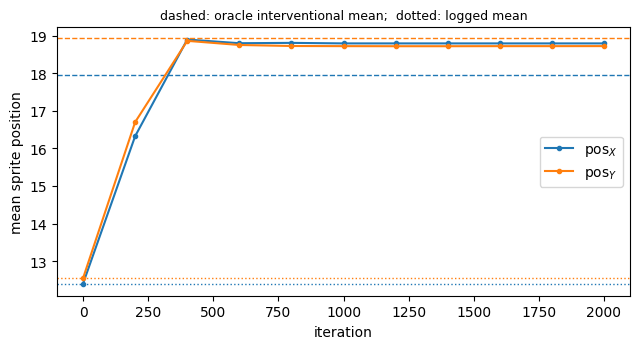

In [7]:
snap_items = sorted(flow_info["snapshots"].items()) + [(2000, flow_particles)]
snap_means = []
for _, snap in snap_items:
    with torch.no_grad():
        imgs = torch.cat([ae.decode(from_flow(snap[i:i + 256]).to(device))
                          for i in range(0, N_OBS, 256)]).reshape(N_OBS, -1)
    snap_means.append(nearest_bank_position(imgs, bank_flat).cpu().float().mean(dim=0))
snap_means = torch.stack(snap_means)
snap_iters = np.array([step for step, _ in snap_items])

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for d, name, color in ((0, r"$\mathrm{pos}_X$", "tab:blue"),
                       (1, r"$\mathrm{pos}_Y$", "tab:orange")):
    ax.plot(snap_iters, snap_means[:, d], marker="o", ms=3, color=color, label=name)
    ax.axhline(float(data["pos_target"][:, d].mean()), color=color, ls="--", lw=1)
    ax.axhline(float(pos_logged[:, d].mean()), color=color, ls=":", lw=1)
ax.set_xlabel("iteration")
ax.set_ylabel("mean sprite position")
ax.set_title("dashed: oracle interventional mean;  dotted: logged mean", fontsize=9)
ax.legend()
plt.tight_layout()
plt.show()

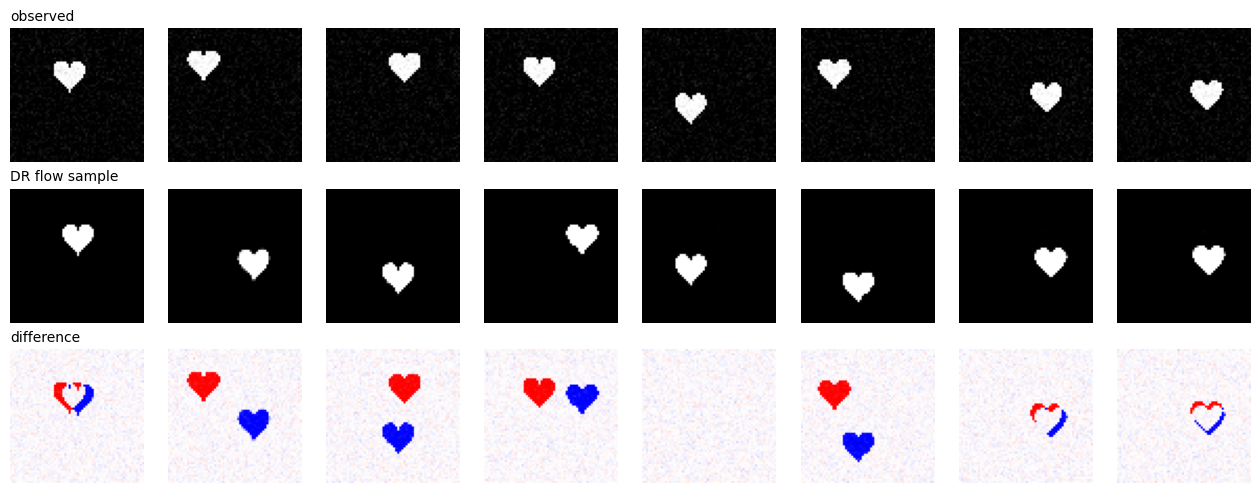

In [8]:
idx = 87
with torch.no_grad():
    obs_show = Y_logged_img[idx:idx + n_show, 0].cpu()
    flow_show = flow_images[idx:idx + n_show].reshape(-1, 64, 64).cpu()
fig, axes = plt.subplots(3, n_show, figsize=(1.6 * n_show, 5.0))
for j in range(n_show):
    axes[0, j].imshow(obs_show[j], cmap="gray", vmin=0, vmax=1)
    axes[1, j].imshow(flow_show[j], cmap="gray", vmin=0, vmax=1)
    axes[2, j].imshow(obs_show[j] - flow_show[j], cmap="bwr", vmin=-1, vmax=1)
for ax in axes.ravel():
    ax.axis("off")
axes[0, 0].set_title("observed", loc="left", fontsize=10)
axes[1, 0].set_title("DR flow sample", loc="left", fontsize=10)
axes[2, 0].set_title("difference", loc="left", fontsize=10)
plt.tight_layout()
plt.show()

## 6. Metric Evaluation

The decoded **position law** is scored against 10 fresh oracle draws of the interventional
position distribution (a single oracle draw is a noisy yardstick at $n = 1000$). Each row
reports mean $\pm$ std over the 10 draws of: the energy distance (squared MMD with the
Riesz kernel) and sliced Wasserstein distances of both orders (1000 projections,
truncation to the smaller sample, following the evaluation code of Dance et al., 2026).
Rows: the logged positions (the no-flow base), the DR-flow positions, and an independent
oracle draw (the finite-sample floor). Off-manifold statistics of the decoded images are
printed alongside.

sample                      energy dist              SW1              SW2


logged (base)            3.9893 +/- 0.190   5.4892 +/- 0.135   6.3213 +/- 0.164


DR Riesz flow            0.0473 +/- 0.012   0.5626 +/- 0.068   0.7049 +/- 0.079


oracle draw (floor)      0.0489 +/- 0.025   0.5644 +/- 0.154   0.6811 +/- 0.168
off-manifold distance: observed decode median 0.36 frac>3 0.000   flowed median 0.48 frac>3 0.044


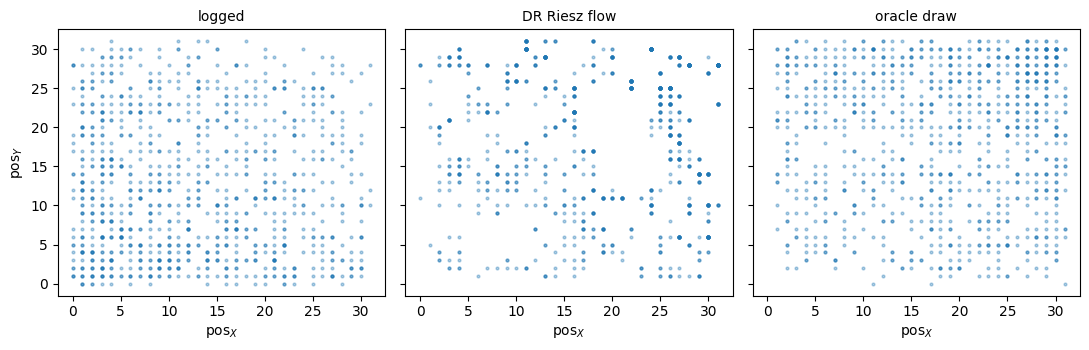

In [9]:
energy_kernel = RieszKernel()
oracle_pos = data["pos_target"].double()

fresh_draws = [sample_cpme_dsprite_data(sprite_bank, n_samples=N_OBS, sigma_policy=0.5,
                                        policy_shift=0.2, pos_gain=3.0,
                                        pixel_noise=0.05, seed=s)["pos_target"].double()
               for s in range(70, 80)]

def score(positions):
    positions = positions.double()
    energy = [float(squared_mmd(energy_kernel, positions, ref)) for ref in fresh_draws]
    sw1 = [float(sliced_wasserstein(positions, ref, p=1, seed=0)) for ref in fresh_draws]
    sw2 = [float(sliced_wasserstein(positions, ref, p=2, seed=0)) for ref in fresh_draws]
    return [(np.mean(vals), np.std(vals)) for vals in (energy, sw1, sw2)]

rows = {"logged (base)": pos_logged,
        "DR Riesz flow": flow_pos,
        "oracle draw (floor)": oracle_pos}
print(f"{'sample':22s} {'energy dist':>16s} {'SW1':>16s} {'SW2':>16s}")
for name, positions in rows.items():
    stats = score(positions)
    print(f"{name:22s} " + " ".join(f"{m:8.4f} +/- {s:.3f}" for m, s in stats))

with torch.no_grad():
    obs_decode = torch.cat([ae(Y_logged_img[i:i + 256]) for i in
                            range(0, N_OBS, 256)]).reshape(N_OBS, -1)
_, obs_offmani = snap_to_bank(obs_decode, bank_flat)
print(f"off-manifold distance: observed decode median {float(obs_offmani.median()):.2f} "
      f"frac>3 {float((obs_offmani > 3).float().mean()):.3f}   "
      f"flowed median {float(flow_offmani.median()):.2f} "
      f"frac>3 {float((flow_offmani > 3).float().mean()):.3f}")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharex=True, sharey=True)
for ax, (name, positions) in zip(axes, (("logged", pos_logged),
                                        ("DR Riesz flow", flow_pos),
                                        ("oracle draw", oracle_pos))):
    ax.scatter(positions[:, 0], positions[:, 1], s=4, alpha=0.35)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel(r"$\mathrm{pos}_X$")
axes[0].set_ylabel(r"$\mathrm{pos}_Y$")
plt.tight_layout()
plt.show()

## 7. Plain Euler Baseline

The fixed-step discretisation of Arbel et al. (2019) with the same Riesz kernel and the
same DR target is step-size fragile in this latent: a small step barely transports (the
energy distance stays near the logged value), while a large step transports the mean at a
cost in manifold fidelity — its decoded off-manifold distance sits well above the AdamW
flow's, and large-step Euler is on the edge of instability (its behaviour varies strongly
across autoencoder trainings). AdamW with warm-up removes this knife-edge.

In [10]:
for step in (0.05, 1.0):
    euler, _ = mmd_gradient_flow(RieszKernel(), flow_target.double(),
                                 initial_particles.double(),
                                 target_weights=v_dr.to(device), step_size=step,
                                 n_iterations=2000, verbose=False)
    with torch.no_grad():
        imgs = torch.cat([ae.decode(from_flow(euler[i:i + 256].cpu().float()).to(device))
                          for i in range(0, N_OBS, 256)]).reshape(N_OBS, -1)
    pos, offmani = snap_to_bank(imgs, bank_flat)
    pos = pos.cpu().float()
    energy = np.mean([float(squared_mmd(energy_kernel, pos.double(), ref))
                      for ref in fresh_draws])
    move = float((euler - initial_particles.double()).norm(dim=1).mean())
    print(f"step {step:4.2f}:  move {move:7.2f}   "
          f"pos mean ({float(pos[:, 0].mean()):.2f}, {float(pos[:, 1].mean()):.2f})   "
          f"energy dist {energy:.4f}   off-manifold median {float(offmani.median()):.2f}")

step 0.05:  move    1.64   pos mean (12.62, 12.78)   energy dist 3.6469   off-manifold median 3.89


step 1.00:  move    3.94   pos mean (18.61, 18.64)   energy dist 0.0429   off-manifold median 0.71


## Summary

- Continuous actions require no change to the DR construction: the action enters only
  through $K_A$ and the Monte Carlo target-kernel mean over $\tilde a \sim \pi(\cdot\mid x)$
  — the binary designs are the special case, not the other way around.
- The fully cross-fitted pipeline (estimated logging density, per-fold conditional mean
  embeddings on shared folds) matches the interventional position law at the oracle
  finite-sample floor on every metric, with the reweighted position diagnostic tracking
  the interventional mean.
- The flow must run in the learned latent: plain pixel-space steps leave the thin sprite
  manifold, and in the latent the plain Euler discretisation is step-size fragile — a
  small step stalls, a large one transports at a cost in manifold fidelity. AdamW with
  warm-up transports at the oracle floor without step tuning; a small off-manifold
  particle tail remains (about 4% past the snap threshold).
- The estimated target policy stays exact throughout ($\pi$ known by design); only
  $\pi_0$ is estimated. A deterministic target $\mathrm{do}(a^*)$ is outside this
  construction's scope.